# Task 4: dead-ball detector

**Owner:** __Matthew__

**Why:** A missing or an invented `D` merges or splits possessions which hurts `spellF1`.

**End Output**
- `pipeline/dead_ball.py`, with a `build()` that returns `{"dead": dead}`, where `dead` is an (N,) bool array, True on dead-ball frames. Here `N=199319` frames.

In [528]:
import sys; sys.path.insert(0, '..')
from pipeline.common import *
import matplotlib.pyplot as plt
import pandas as pd
import xml.etree.ElementTree as ET

trk = load_tracking()          # ball, ball_speed, players, player_speed, team -- all in metres
gt = load_public_gt()          # public ground truth, X outside the 5-minute window
graded = graded_mask()         # True for frames the scorer grades
half = half_of_frame()         # 1 (first half), 2 (second half), or 0 (pre-match, halftime, postmatch)
stage = load_stage("ball_filled")
PUBLIC = np.flatnonzero(gt != 'X')[[0, -1]]        # the 5 minutes we have ground truth for (inclusive)

# Section 1 - Aligning data
Here we put tracking and tags on the same index. This organises the tracking data as a pandas dataframe.

In [529]:
# We first get the number of players, and label each by team
S = trk['players'].shape[1]
team_name = np.where(trk['team'] == HOME, 'home', 'away')

# We get the player's coordinates and speed
# one (x, y, speed) triple per slot, labelled (team, slot, variable)
player_vals = np.concatenate(
    [trk['players'], trk['player_speed'][:, :, None]], axis=2
).reshape(N_FRAMES, S * 3)

player_cols = pd.MultiIndex.from_tuples(
    [(team_name[s], s, v) for s in range(S) for v in ('x', 'y', 'speed')],
    names=['team', 'slot', 'var'],
)
players_df = pd.DataFrame(player_vals, columns=player_cols)


# Ball: same three levels, with slot left empty
ball_df = pd.DataFrame(
    np.column_stack([trk['ball'], trk['ball_speed']]),
    columns=pd.MultiIndex.from_tuples(
        [('ball', '', 'x'), ('ball', '', 'y'), ('ball', '', 'speed')],
        names=['team', 'slot', 'var'],
    ),
)

trk_df = pd.concat([ball_df, players_df], axis=1)
trk_df.index.name = 'frame'

In [530]:
trk_df.head()

team  ball                 home                                         ...  \
slot                          0                        1             2  ...   
var      x   y speed          x          y     speed   x   y speed   x  ...   
frame                                                                   ...   
0      NaN NaN   NaN  35.181782  61.584202  0.886863 NaN NaN   NaN NaN  ...   
1      NaN NaN   NaN  35.174412  61.531158  0.886863 NaN NaN   NaN NaN  ...   
2      NaN NaN   NaN  35.165989  61.480839  0.886863 NaN NaN   NaN NaN  ...   
3      NaN NaN   NaN  35.158615  61.433922  0.886863 NaN NaN   NaN NaN  ...   
4      NaN NaN   NaN  35.151245  61.389721  0.886863 NaN NaN   NaN NaN  ...   

team   away                                                         
slot     42  43            44                  45                   
var   speed   x   y speed   x   y speed         x          y speed  
frame                                                               
0       NaN NaN NaN   NaN NaN NaN   NaN  6.378021  27.176201   NaN  
1       NaN NaN NaN   NaN NaN NaN   NaN  6.378021  27.176201   NaN  
2       NaN NaN NaN   NaN NaN NaN   NaN  6.378021  27.176201   NaN  
3       NaN NaN NaN   NaN NaN NaN   NaN  6.378021  27.176201   NaN  
4       NaN NaN NaN   NaN NaN NaN   NaN  6.378021  27.176201   NaN  

[5 rows x 141 columns]

This turns the smart tagging xml file into a pandas dataframe.

In [531]:
root = ET.parse('../data/tactical/BAR-ATH_tactical_smart_tagging.xml').getroot()

rows = []
for inst in root.iter('instance'):              # every <instance> in the file
    row = {
        'ID': int(inst.findtext('ID')),
        'start': float(inst.findtext('start')),
        'end': float(inst.findtext('end')),
        'code': inst.findtext('code'),
    }
    for lab in inst.findall('label'):           # turn each <group>/<text> pair into a column
        row[lab.findtext('group')] = lab.findtext('text')
    rows.append(row)

tags = pd.DataFrame(rows).sort_values('start').reset_index(drop=True)


In [532]:
tags['start_frame'] = round(tags.start * 25).astype(int)
tags['end_frame'] = round(tags.end * 25).astype(int)

In [533]:
tags.head()

,ID,start,end,code,Team,Type,Half,Max Players in the box,Side,Direction of ball entry,start_frame,end_frame
0,104,442.76,513.60,BALL IN FINAL THIRD,Atletic Club,NaN,1st Half,4,Central,NaN,11069,12840
1,404,443.40,454.76,LONG BALL,Atletic Club,NaN,1st Half,NaN,NaN,NaN,11085,11369
2,1,443.88,448.88,SET PIECES,N/A,Kick Off (Start),1st Half,NaN,NaN,NaN,11097,11222
3,543,448.16,480.84,DEFENDING IN MIDDLE THIRD,Barcelona,NaN,1st Half,NaN,NaN,NaN,11204,12021
4,319,448.16,480.84,PROGRESSION,Atletic Club,NaN,1st Half,NaN,NaN,NaN,11204,12021


# Section 2 - Generating labels

This section builds an (N,) label for each feature below. Each label could be `-1` meaning that the indicator thinks the ball is dead, `1` meaning the ball is live, and `-1` (no info) meaning an abstention.

| Feature | `-1` when | Source | Output |
|---|---|---|---|
| **Out of bounds and Gaps** | Around a gap from task 3, and (1) the ball is last seen out of bounds (2) the gap follows a set piece. | Start and end of a stoppage | `build_out_of_bounds()`, `build_long_gaps()` 
| **Goal** | Around a gap from task 3, and (1) the ball is near a goal mouth (2) the gap is around a `GOALS` tag (3) the gap is long enough | Ball coordinates + `frame_tags` | `build_goal_dead()` |
| **Ball stationary/ restart** | Ball speed is below a threshold/ accelerates sharply | Ball speed from task 3 |`build_stoppage()`, `build_restart_kick()`|
| **Player slowdown** | Average player speed plateaus | Player speeds in `trk_df` |`build_slowdown()`|
| **Tags** | Smart tagging indicates an event indicative of a dead ball occurs. | `frame_tags` |`build_tag_stoppage()`|


## 1. Out of bounds and Gaps
This section generates labels based on if the ball is out of the field (bounds). We use gaps from Task 3.

### Information

1. From Task 3, we have frames between which the ball is out of bounds. In particular, the values in `stage['gap_start']` and `stage['gap_end']` with the same indicies mark a gap, for which the `stage['gap_exit_out']` indicates if the ball was out of bounds. This is a strong signal.

2. From Task 3, we also have long gaps. We want to check if there is a `SET_PIECE` near when the gap ends. This would also be a strong signal. 

Here we build `build_out_of_bounds()` and `build_long_gaps()`, both (N,) arrays. `-1` indicates dead balls, `0` indicates an abstention.

In [534]:
OUT_OF_BOUNDS_CONFIG = {
    'look_ahead_seconds': 2, # we look this far ahead on a long gap's end (point 2) to check for a set piece tag
    'look_beyond_seconds': 4, # we look this far after on a long gap's end (point 2) to check for a set piece tag
}

In [ ]:
def build_out_of_bounds(): # this handles out of bounds for gaps
    """(N,) -1 on all gaps in staged ball location where gap_exit_out is indicated True, 0 otherwise."""
    out_of_bounds = np.zeros(N_FRAMES)
    
    exited_gap_starts = stage['gap_start'][stage['gap_exit_out']]
    exited_gap_ends = stage['gap_end'][stage['gap_exit_out']]

    for start, end in zip(exited_gap_starts, exited_gap_ends):
        out_of_bounds[start: end + 1] = -1 
    
    return out_of_bounds

def build_long_gaps(): # this handles non-out of bounds for gaps, with set pieces following
    """(N,) -1 on non-out-of-bounds ball gaps with a SET PIECES tag ending near the gap's end, 0 elsewhere."""
    long_gaps = np.zeros(N_FRAMES)
    
    look_ahead_frames = FPS * OUT_OF_BOUNDS_CONFIG['look_ahead_seconds'] 
    look_beyond_frames = FPS * OUT_OF_BOUNDS_CONFIG['look_beyond_seconds'] 

    keep = ~stage['gap_exit_out'] # we only concern ourselves with when the gap doesn't correspond to an out of bounds. 
    starts, ends = stage['gap_start'][keep], stage['gap_end'][keep] 
    set_piece_frames = np.sort(tags.loc[tags['code'] == 'SET PIECES', 'end_frame'].to_numpy())

    # number of set-piece frames inside [end - critical, end + critical], for every gap at once
    lo = np.searchsorted(set_piece_frames, ends - look_ahead_frames, side='left')
    hi = np.searchsorted(set_piece_frames, ends + look_beyond_frames, side='right')
    hit = hi > lo

    for s, e in zip(starts[hit], ends[hit]):
        long_gaps[s:e] = -1
    
    return long_gaps

## 2. Goal
This section generates labels based on if the ball is in a goal. Again we use gaps from Task 3.

### Information

Tracking data loses the ball every time before the goal as it is never recorded having crossed the goal line between the posts. We want to fill this gap from task 3. After a goal typically follows a long delay where replays/ walk-backs/ celebration happen. We check for all these: 
1. if the ball is over the goal line from the cooridnates in task 3
2. if smart_tagging says `GOAL`
3. if the gap is sustained long enough. 

We build `build_goal_dead()`. `-1` indicates certainly dead balls, and `0` indicates abstention,

In [536]:
GOAL_CONFIG = {
    'distance_from_goal_line': 12,      # The 4 foals last seen at 7.9, -2.6, 6.9, 9.6 away from the goal line. 12 provides room to spare.
    'distance_from_goal_centre_y': 5,   # The 4 goals last seen at 0.7, 12.7, 1.8, 2.9 meter away from the goal line. 5 provides room to spare
    'gap_length_seconds': 30,           # How long do we consider a length to be 'long',
}

In [537]:
def last_seen_before(starts):
    """(G, 2) ball position on the frame before each gap starts. Clamped so a gap on frame 0 doesn't wrap to -1."""
    return stage['ball'][np.maximum(starts - 1, 0)]


def near_goal_mouth(points, cfg=GOAL_CONFIG):
    """(G,) bool: point is within distance_from_goal_line of either goal line and close to the pitch's centre line in y."""
    length, width = PITCH
    dist_to_goal_line = np.minimum(points[:, 0], length - points[:, 0])
    dist_to_centre_y = np.abs(points[:, 1] - width / 2)
    return (dist_to_goal_line < cfg['distance_from_goal_line']) & (dist_to_centre_y < cfg['distance_from_goal_centre_y'])


def tag_mask(code):
    """(N,) bool: True on every frame covered by a smart-tagging entry with this code."""
    mask = np.zeros(N_FRAMES, bool)
    for s, e in tags.loc[tags['code'] == code, ['start_frame', 'end_frame']].to_numpy():
        mask[s:e + 1] = True
    return mask


def gaps_overlapping(mask, starts, ends):
    """(G,) bool: the gap contains at least one True frame of mask."""
    return np.array([mask[s:e].any() for s, e in zip(starts, ends)], dtype=bool)


def paint_gaps(starts, ends, value=-1):
    """(N,) array: value on every frame of the given gaps, 0 elsewhere."""
    out = np.zeros(N_FRAMES, dtype=int)
    for s, e in zip(starts, ends):
        out[s:e] = value
    return out

In [538]:
def build_goal_dead(cfg=GOAL_CONFIG):
    """(N,) -1 on gaps where the ball was (1) last seen near a goal mouth, (2) gone long enough, (3) during a GOALS tag. 0 otherwise."""
    starts, ends = stage['gap_start'], stage['gap_end']

    near_goal = near_goal_mouth(last_seen_before(starts), cfg)               # (1)
    long_enough = (ends - starts) >= cfg['gap_length_seconds'] * FPS         # (2)
    overlaps_tag = gaps_overlapping(tag_mask('GOALS'), starts, ends)         # (3)

    is_goal_gap = near_goal & long_enough & overlaps_tag
    return paint_gaps(starts[is_goal_gap], ends[is_goal_gap])

## 3. Ball Stationary/ Restart

This checks for two things: 
1. **When the ball goes quiet**. This detects when there is a long, sustained spell of low ball speeds. This happens when, say, someone is fetching the ball, places it somewhere and waits. This builds `still_stoppage`.
2. **When the ball is kicked from rest**. This detects when a ball experiences sudden jump in speed after a quiet spell, with a player nearby. This builds `restart_kick`.


In [539]:
STILL_CONFIG = dict(
    # still stopage
    median_frames=12*FPS,    # 12 s rolling median: heavy smoothing, picks out sustained low-speed spells
    V0=3.0,                  # m/s: at or below this the ball counts as still
    gap_mode='freeze',       # what a missing ball does to the counter: 'reset' to 0 or 'freeze' (hold)
    N_still_s=2.0,           # seconds the ball must be still before a spell counts as a stoppage / a kick as a restart
    # restart_kick
    kick_median_frames=8,   # rolling median for kick detection: light, so the kick's jump in speed survives
    look_s=1.0,              # s: the stillness only has to be this recent, not on the frame right before the kick
    V_kick=6.0,              # m/s: speed that counts as a kick
    R_player=3.0,            # m: the nearest player must be this close to the ball at the kick
)

In [540]:
def compute_ball_speed():
    """(N,) float: ball speed by taking displacement between frames, nan if position missing"""
    displacement = np.diff(stage['ball'], axis=0, prepend=np.full((1, 2), np.nan))  
    return np.linalg.norm(displacement, axis=1) * FPS                               

def smooth_speed(speed, frames=5):
    """(N,) float: Centred rolling median of the speed. Frames with no speed stay NaN (no filling)."""
    v = pd.Series(speed).rolling(frames, center=True, min_periods=1).median().to_numpy()
    return np.where(np.isnan(speed), np.nan, v)

def stillness_counter(v, V0, gap_mode='reset'):
    """(N,) int: consecutive frames with v <= V0. A missing frame resets the count or holds it, never adds to it."""
    still_frames = np.zeros(len(v), dtype=int)
    count = 0
    for t, value in enumerate(v):
        if np.isnan(value):
            count = 0 if gap_mode == 'reset' else count # missing frames reset count
        elif value <= V0:
            count += 1
        else:
            count = 0 
        still_frames[t] = count
    return still_frames


def nearest_player_distance(ball, players):
    """(N,) metres from the ball to the closest player. NaN if there is no ball or no player."""
    dist = np.linalg.norm(players - ball[:, None, :], axis=2)
    dist = np.where(np.isnan(dist), np.inf, dist).min(axis=1) # so say [2, 3, NaN] -> [2, 3, inf] -> 2
    
    return np.where(np.isinf(dist), np.nan, dist)


def restart_kicks(v, still_frames, near_dist, N_still_s, V_kick, R_player, look_s=1.0, fps=FPS):
    """(N,) bool, True on the first frame of each kick that comes within look_s of N_still_s seconds of stillness.

    The stillness only has to be recent: on the way from <= V0 up to > V_kick the speed passes through
    the band in between, which resets the counter, so requiring it on the frame right before never fires.
    """
    still_enough = still_frames >= N_still_s * fps
    recent = (pd.Series(still_enough).rolling(int(look_s * fps), min_periods=1).max()
              .shift(1, fill_value=0).astype(bool).to_numpy())             # still at some point in the last look_s
    kick = recent & (v > V_kick) & (near_dist <= R_player)                 # NaN comparisons are False
    return kick & ~np.r_[False, kick[:-1]]                                 # keep the first frame of each run


def stoppage_from_stillness(still_frames, N_still_s, fps=FPS):
    """(N,) bool: every frame of a still spell that lasts at least N_still_s seconds."""
    stoppage = np.zeros(len(still_frames), dtype=bool)
    for is_still, start, end in runs(still_frames > 0):
        if is_still and still_frames[start:end].max() >= N_still_s * fps:
            stoppage[start:end] = True
    return stoppage


In [541]:
def build_stoppage(cfg=STILL_CONFIG):
    """(N,) -1 on every frame of a sustained low-speed spell (heavy smoothing), 0 otherwise."""
    v = smooth_speed(compute_ball_speed(), cfg['median_frames'])
    still_frames = stillness_counter(v, cfg['V0'], cfg['gap_mode']) # so each frame gets the length of the still run
    still_stoppage = stoppage_from_stillness(still_frames, cfg['N_still_s'])
    return np.where(still_stoppage, -1, 0)


def build_restart_kick(cfg=STILL_CONFIG):
    """(N,) -1 on the first frame of each kick from rest with a player nearby (light smoothing), 0 otherwise."""
    near_dist = nearest_player_distance(stage['ball'], trk['players'])
    v_kick = smooth_speed(compute_ball_speed(), cfg['kick_median_frames'])    # light, so the jump in speed survives
    still_frames_kick = stillness_counter(v_kick, cfg['V0'], cfg['gap_mode'])
    restart_kick = restart_kicks(v_kick, still_frames_kick, near_dist, cfg['N_still_s'],
                                 cfg['V_kick'], cfg['R_player'], cfg['look_s'])
    return np.where(restart_kick, -1, 0)


still_stoppage = build_stoppage()
restart_kick = build_restart_kick()

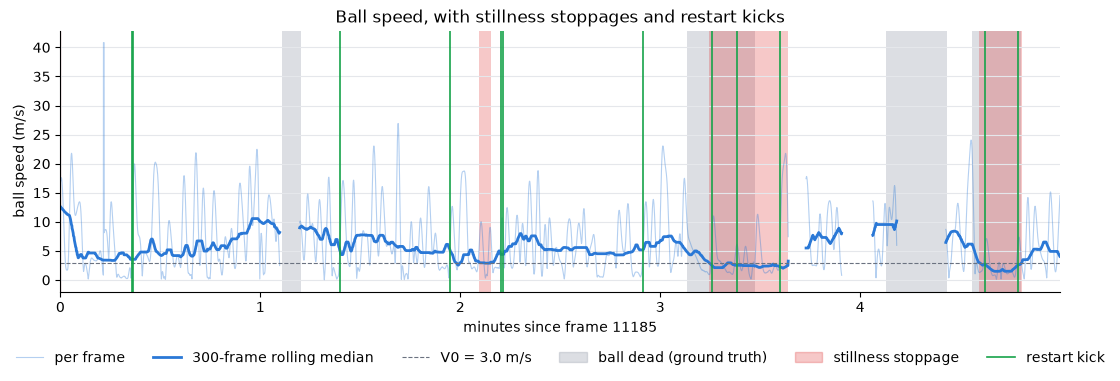

In [542]:
def plot_indicators():
    # ---- plot: same graph as above, stillness stoppages in red, restart kicks in green ----
    cfg = STILL_CONFIG
    ball_speed = compute_ball_speed()
    v = smooth_speed(ball_speed, cfg['median_frames'])

    first, last = PUBLIC
    frames = np.arange(first, last + 1)
    minutes = (frames - first) / FPS / 60
    dead = gt[first:last + 1] == 'D'
    ours = still_stoppage[first:last + 1] == -1
    kicks = np.flatnonzero(restart_kick[first:last + 1])

    fig, ax = plt.subplots(figsize=(12, 4))

    # ground-truth stoppages: grey
    for label, start, end in runs(dead):
        if label:
            ax.axvspan(minutes[start], minutes[end - 1], color='#9ca3af', alpha=0.35, lw=0)

    # our stillness stoppages: red (darker where they overlap the grey, i.e. where we agree)
    for label, start, end in runs(ours):
        if label:
            ax.axvspan(minutes[start], minutes[end - 1], color='#dc2626', alpha=0.25, lw=0)

    ax.plot(minutes, ball_speed[first:last + 1], color='#2a78d6', lw=0.8, alpha=0.35, label='per frame')
    ax.plot(minutes, v[first:last + 1], color='#2a78d6', lw=2, label=f"{cfg['median_frames']}-frame rolling median")
    ax.axhline(cfg['V0'], color='#6b7280', lw=0.8, ls='--', label=f"V0 = {cfg['V0']} m/s")
    for k in kicks:
        ax.axvline(minutes[k], color='#16a34a', lw=1.2)
    ax.axvspan(0, 0, color='#9ca3af', alpha=0.35, label='ball dead (ground truth)')    # legend entries only
    ax.axvspan(0, 0, color='#dc2626', alpha=0.25, label='stillness stoppage')
    ax.axvline(-1, color='#16a34a', lw=1.2, label='restart kick')

    ax.set_xlim(minutes[0], minutes[-1])
    ax.set_xlabel(f'minutes since frame {first}')
    ax.set_ylabel('ball speed (m/s)')
    ax.set_title('Ball speed, with stillness stoppages and restart kicks')
    ax.grid(axis='y', color='#e5e7eb', lw=0.8)
    ax.spines[['top', 'right']].set_visible(False)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=6, frameon=False)
    fig.tight_layout()
    
plot_indicators()

This shows that stillness stoppage is a decent indicator, yet restart kick is not so. However, it is a sharp signal for the end of a spell of dead frames. The latter also only indicates a restart so doesn't contribute to the per frame vote. So we want to just use this to adjust runs of dead frames we find. We will just drop this for now.

## 4. Player Slowdown
This section generates labels based on if the players collectively slow down. We use player speeds from the tracking data.

### Investigation

Let's get the speed of all players that are within the same radius `R` of the ball, `avg_speed_near_ball`.

In [543]:
def average_player_speed_near_ball(R=60):

    # go to each slot, work out the norm between the coordinate to the ball coordinate
    dist = np.linalg.norm(trk['players'] - stage['ball'][:, None, :], axis=2)       # (N, S) distance of every player to the ball

    # only include players within R of the ball that have a speed reading
    speed = trk['player_speed']
    near = (dist <= R) & ~np.isnan(speed)                                  # (N, S) True = counts towards the average

    # on each frame, calculate the average speed of those players
    n_near = near.sum(axis=1)                                              # players counted per frame
    speed_sum = np.where(near, speed, 0).sum(axis=1)                       # their total speed
    avg_speed_near_ball = np.where(n_near > 0, speed_sum / np.maximum(n_near, 1), np.nan)   # NaN if nobody is near

    return avg_speed_near_ball

def plot_player_average_speed_near_ball():
        
        # plot a graph of the avg_speed_near_ball on the first 5 minutes (covered by the ground truth)
        first, last = PUBLIC
        frames = np.arange(first, last + 1)
        minutes = (frames - first) / FPS / 60                        # x-axis: minutes into the window
        window_speed = average_player_speed_near_ball()[first:last + 1]
        dead = gt[first:last + 1] == 'D'

        fig, ax = plt.subplots(figsize=(12, 4))

        # shade the graph where the ground truth says the ball is dead (one band per run of dead frames)
        for label, start, end in runs(dead):
                if label:
                        ax.axvspan(minutes[start], minutes[end - 1], color='#9ca3af', alpha=0.3, lw=0)

        ax.plot(minutes, window_speed, color='#2a78d6', lw=0.8, alpha=0.35, label='per frame')
        ax.plot(minutes, pd.Series(window_speed).rolling(FPS, center=True, min_periods=1).mean(),
                color='#2a78d6', lw=2, label='1 s rolling mean')
        ax.axvspan(0, 0, color='#9ca3af', alpha=0.3, label='ball dead (ground truth)')   # legend entry only

        ax.set_xlabel(f'minutes since frame {first}')
        ax.set_ylabel('speed (m/s)')
        ax.set_title(f'Average speed of players within {R} m of the ball')
        ax.grid(axis='y', color='#e5e7eb', lw=0.8)
        ax.spines[['top', 'right']].set_visible(False)
        ax.legend(loc='upper right', frameon=False)
        fig.tight_layout()

By running the cell below, we plot a graph of the average player speed around `R` of the ball against the ground truth. We observe that instances when the ball falls below 1 m/s, and tag the immediately preceding 
1. sharp decline 
2. sharp decline and pleateau, 
3. missing data, 
that is likely a stoppage.

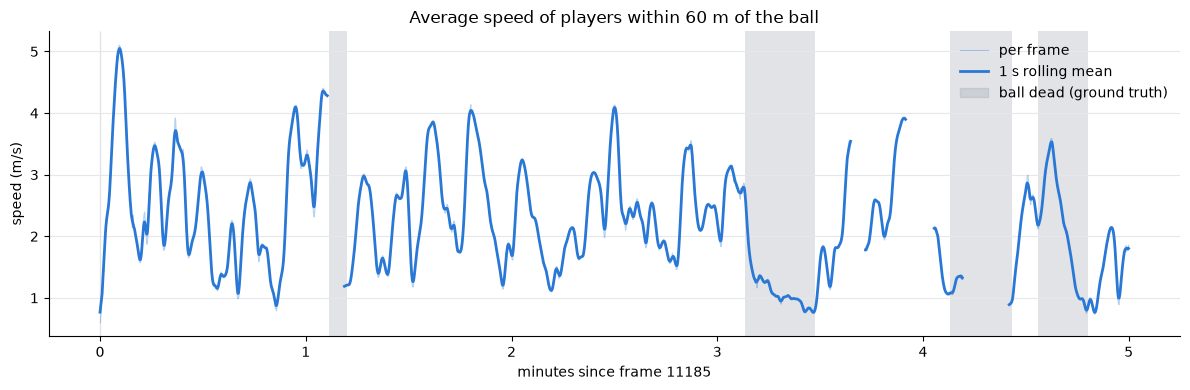

In [544]:
plot_player_average_speed_near_ball()

### Information

1. From the graph below, we observe that dead balls typically precede frames where ball speed is below a certain threshold `low`. This stretches back from the previous sharp deceleration `sharp_decline`, and usually ends right before a sharp acceleration `steep_rise` that follows.

2. We also observe a dead ball is very unlikely when the ball speed is above a certain threshold `high`.


We build `build_slowdown()`. This marks balls who fits description 1 `-1` (dead), and that fitting description 2 `1` (live). For all other frames, this indicator abstain `0`.

In [545]:
PLAYER_SLOWDOWN_CONFIG = dict(
    low=1.0,                    # m/s: average speed at or below this counts as "slowed down"
    high=1.8,                   # m/s: above this, players are "certainly alive"
    steep_decline=-15,          # m/s²: slope below this is a sharp slowdown (h1)
    steep_rise=0.5,             # m/s²: slope above this is players speeding up again (h2)
    look_back_seconds=15,       # how far before a low period to search for the decline / previous peak
    look_ahead_seconds=5,       # how far after it to search for the speed-up
    min_low_seconds=4,          # how long players near the ball must stay slow to count as a stoppage
    peak_tol=0.5,               # m/s: bumps smaller than this don't count as a peak
)

In [546]:
def smooth_and_slope(speed, fps=FPS):
    """Fill NaNs, smooth with a 1 s rolling mean, and differentiate. Returns (smooth m/s, slope m/s²)."""
    filled = pd.Series(speed).interpolate(limit_direction='both')
    smooth = filled.rolling(fps, center=True, min_periods=1).mean().to_numpy()
    slope = np.gradient(smooth) * fps
    return smooth, slope


def block_start(mask, i):
    """Walk back from frame i to the first frame of the True block it sits in."""
    while i > 0 and mask[i - 1]:
        i -= 1
    return i


def last_block_before(mask, start, look_back):
    """First frame of the most recent True block in the look_back frames up to `start`, or None."""
    lo = max(start - look_back, 0)
    hits = np.flatnonzero(mask[lo:start])
    return block_start(mask, lo + hits[-1]) if len(hits) else None


def find_stoppage_start(start, steep_down, missing, look_back):
    """Move a low spell's start back over the steep decline before it, then over any missing block before that."""
    stoppage_start = start
    i = last_block_before(steep_down, stoppage_start, look_back)
    if i is not None:
        stoppage_start = min(stoppage_start, i)
    i = last_block_before(missing, stoppage_start + 1, look_back + 1)    # +1: includes stoppage_start itself
    if i is not None:
        stoppage_start = min(stoppage_start, i)
    return stoppage_start


def find_stoppage_end(end, slope, h2, look_ahead):
    """First frame within look_ahead after a low spell where players speed up again (slope > h2)."""
    rising = np.flatnonzero(slope[end:end + look_ahead] > h2)
    return end + rising[0] if len(rising) else end


def previous_peak(start, smooth, ball_missing, look_back, tol):
    """Walk back from `start` to the last speed peak, stopping at a missing ball or a drop of more than tol."""
    i = peak = start
    while i > max(start - look_back, 0) and not ball_missing[i - 1] and smooth[i - 1] >= smooth[peak] - tol:
        i -= 1
        if smooth[i] > smooth[peak]:
            peak = i
    return peak

def ball_missing():
    return np.isnan(stage['ball'][first:last + 1, 0])

In [547]:
def build_slowdown(cfg=PLAYER_SLOWDOWN_CONFIG):
    """(len(speed),) -1 where players near the ball slow to a stop, 1 where they are clearly running, 0 otherwise."""
    slowdown = np.zeros(N_FRAMES)
        
    speed = average_player_speed_near_ball()
    ball_missing = np.isnan(stage['ball'][:, 0])  

    look_back, look_ahead = int(cfg['look_back_seconds'] * FPS), int(cfg['look_ahead_seconds'] * FPS)
    min_low = int(cfg['min_low_seconds'] * FPS)

    missing = np.isnan(speed)
    smooth, slope = smooth_and_slope(speed, FPS)
    steep_down = slope < cfg['steep_decline']

    # 1. every sustained low spell, stretched back over its slowdown and forward to the restart
    for is_low_spell, start, end in runs(smooth <= cfg['low']):
        if is_low_spell and end - start >= min_low:
            s = find_stoppage_start(start, steep_down, missing, look_back)
            e = find_stoppage_end(end, slope, cfg['steep_rise'], look_ahead)
            slowdown[s:e] = -1

    # 2. stretch each stoppage back to the last speed peak before it
    for is_dead, start, end in runs(slowdown == -1):
        if is_dead:
            slowdown[previous_peak(start, smooth, ball_missing, look_back, cfg['peak_tol']):start] = -1

    # 3. clearly running and not a stoppage: alive
    slowdown[(smooth > cfg['high']) & (slowdown != -1)] = 1
    return slowdown

## 5.Tags
This section generates labels based on the smart tagging data. We build `build_tags()`, using the tags below from the smart tracking data. `1` means certainity alive, `-1` means certainly dead, and `0` means an abstention.

In [548]:
TAGS_CONFIG = dict(
    stoppage_tags = np.array([
        'GOALS', 
        'SET PIECES'
        ]),
    alive_tags = np.array([
        'PROGRESSION',
        'DEFENDING IN MIDDLE THIRD',
        'ATTACKING TRANSITION',
        'DEFENSIVE TRANSITION',
        'LONG BALL',
        'BUILD UP',
        'DEFENDING IN ATTACKING THIRD'
        ])
)

In [549]:
def apply_tag(category_tags, label):
    
    out = np.zeros(N_FRAMES)
    for tag in category_tags:
        # go to tags, and find all entries with the same tag
        entries = tags[tags['code'] == tag]
        # for each entry, take the start frame and end frame
        for start, end in zip(entries['start_frame'], entries['end_frame']):
            # turn all the indices between start frame and end frame in arr 0
            out[start:end + 1] = label   # +1 so end_frame itself is included
    return out


def build_tags_stoppage():
    """(N,) array for stoppages. -1 for dead frames, 1 for alive frames"""
    stoppage_arr = np.full(N_FRAMES, np.nan)
    stoppage_arr = apply_tag(TAGS_CONFIG['stoppage_tags'], -1)

    alive_arr = np.full(N_FRAMES, np.nan)
    alive_arr = apply_tag(TAGS_CONFIG['alive_tags'], 1)

    return alive_arr + stoppage_arr # Note if a cell is dead and alive, the model abstain. (As -1 + 1 = 0)

## 6. Aggregating the votes

| Indicator | Reliability (0-1) | Explanation |
|---|---|---|
| `indicator_out_of_bounds` | **0.6** | Using the ground truth, we calculated precision to be 0.61. This is consistent as the gap is marked from when the ball leaves, but play is often only stopped later, and the ball can briefly return before the restart, so the edges disagree with the ground truth.|
| `indicator_long_gaps` | **0.6** | This is only fired on only 2 frames of the public window, so it is effectively untested. However, this requires both (1) a long gap to be detected (2) a set piece to be near the end. This is a strong requirement. |
| `indicator_goal` | **0.8** | Requires three separate conditions: (1)ball lost near a goal mouth (2) a long gap (3) and a `GOALS` tag), so a false alarm is very unlikely. There is no goal in the public window, so this value is from reasoning only and is not tested. |
| `indicator_still_stoppage` | **0.3** | Weak: precision 0.66, recall 0.45. A dead ball keeps moving while players fetch and place it, and a live ball is often slow. Useful only as a tiebreaker. |
| `indicator_restart_kicks` | **0** | Excluded from the vote. It marks single frames, only 4 of 12 firings land in dead play, and it hits just 2 of the 4 restarts. So this is a weak signal. We ignore this for now, |
| `indicator_player_slowdown` | **0.8** | Strongest signal on the public window: `-1` is right 85% of the time and finds 84% of dead frames; `+1` is right 96% of the time. It's the only indicator that votes confidently both ways, so it carries the most weight. |
| `indicator_tags` | **0.7** | In the ground truth, `-1` was right 77% of the time. The only issue is that tag boundaries are loose (a `SET PIECES` tag spans the set piece and some play after it), so it gets less weight than `slowdown`. |






In [ ]:
EVAL_CONFIG = dict(
    MAX_LIVE_GAP_S = 2,          # a live gap this short between two dead spells is the same stoppage
    MIN_DEAD_S = 1,              # a dead gap this short between two live spells is the same live spell
    DEAD_THRESHOLD = -0.6  
)

We also want to fill over short gaps. For example, a dead spell less than `MIN_DEAD_S` between two live spells certainly belongs to the live spell. We want to fill over these.

In [591]:
def fill_short_gaps(mask, max_s, fill_with, fps=FPS):
    """(N,) bool: mask, with every run of (not fill_with) lasting at most max_s seconds,
    sitting between two runs of fill_with, set to fill_with.

    fill_with=True  -> short live gaps between dead spells become dead
    fill_with=False -> short dead spells between live spells become live
    Runs at the very start or end of the match are left alone.
    """
    mask = mask.copy()
    spans = runs(mask)
    for i, (label, start, end) in enumerate(spans):
        enclosed = 0 < i < len(spans) - 1          # this just check if it isn't the fist or last run, we want to skip them because they are not between anything
        if label != fill_with and enclosed and end - start <= max_s * fps:
            mask[start:end] = fill_with
    return mask

def evaluate_score():
    indicators_weightings = dict(
        indicator_out_of_bounds = 0.6,
        indicator_long_gaps = 0.6,
        indicator_goal = 0.8,
        indicator_still_stoppage = 0.3,
        indicator_restart_kicks = 0,
        indicator_player_slowdown = 0.8,
        indicator_tags = 0.7,
    )
    indicators_values = dict(
        indicator_out_of_bounds = build_out_of_bounds(),
        indicator_long_gaps = build_long_gaps(),
        indicator_goal = build_goal_dead(),
        indicator_still_stoppage = build_stoppage(),
        indicator_restart_kicks = build_restart_kick(),
        indicator_player_slowdown = build_slowdown(),
        indicator_tags = build_tags_stoppage(),
    )
    
    names = list(indicators_values)                                   
    values = np.vstack([indicators_values[n] for n in names])               # (K, N): one row per indicator
    weights = np.array([indicators_weightings[n] for n in names])           # (K,)
    score = weights @ values                                                # (N,): weighted sum per frame
    return score 

def build():
    """{'dead': (N,) bool}: weighted score below DEAD_THRESHOLD, short live gaps filled, then dead flickers removed."""
    dead = evaluate_score() < EVAL_CONFIG['DEAD_THRESHOLD']
    dead = fill_short_gaps(dead, EVAL_CONFIG['MAX_LIVE_GAP_S'], fill_with=True)     # join stoppages split by a brief live gap
    dead = fill_short_gaps(dead, EVAL_CONFIG['MIN_DEAD_S'], fill_with=False)        # remove dead flickers inside live play
    return {'dead': dead}

In [593]:
build()

{'dead': array([ True,  True,  True, ..., False, False, False], shape=(199319,))}

# Section 3 - Evaluation and Fine-Tuning

Running the cell below for evaluation results, we see that our methodology improves `f1_D`, and through it `spell_f1_mean` and `poss`.

| Metric | Result |
|---|---|
| `f1_D` | The F1 score (precision and recall combined) on dead frames. It improves at every smoothing window, by +0.38 (raw) to +0.71 (`smooth125`), and by **+0.51 at `smooth50`** (0.32 → 0.83), the published baseline window. |
| `spell_f1_mean` | The ranking metric. It rises from 0.326 to **0.380** at `smooth50`. There is no gain at `raw` or `smooth25`, where the baseline's flicker between H and A dominates and a dead-ball detector cannot fix it. |
| `poss` | The ground truth has 17 possessions (`EVALUATION.md:127`). At `smooth50` our predicted count falls from 26 to 24, a small step towards 17; at `smooth25` it is unchanged (36). |

These numbers come from the public 5 minutes only (17 possessions), so read them as a direction, not a verdict (`EVALUATION.md:125-140`).


In [592]:
# Baseline vs baseline + our dead-ball mask, scored on the public window with the official scorer.
# Same setup as Task 3's comparison. Submissions go to a temp folder, not evaluation/results.
import os, subprocess, tempfile
sys.path.insert(0, os.path.join("..", "starter"))
import baseline as bl

codes = bl.build()                                    # nearest player's team to the tracking ball, NOBODY where missing
dead = build()["dead"]                                # (N,) bool from this notebook

def with_dead(labels):
    """Smoothed labels with D forced on every frame our detector calls dead."""
    out = labels.copy()
    out[dead] = 'D'
    return out

variants = {
    'baseline':      lambda w: bl.smooth(codes, w),
    'baseline-dead': lambda w: with_dead(bl.smooth(codes, w)),
}

first, last = PUBLIC
in_window = dead[first:last + 1]
print(f"dead on {dead.mean():.1%} of the match, {in_window.mean():.1%} of the public window "
      f"(ground truth: {(gt[first:last + 1] == 'D').mean():.1%}); "
      f"precision {(gt[first:last + 1][in_window] == 'D').mean():.2f}")

out = tempfile.mkdtemp()
for w in (0, 25, 50, 125):
    window = f"smooth{w}" if w else "raw"
    for name, make in variants.items():
        bl.write_submission(os.path.join(out, "results", f"{name}_{window}.csv"), make(w))
subprocess.run([sys.executable, os.path.join("..", "evaluation", "run_evaluation.py"), "--gt", "public", "--no-detail",
                "--results", os.path.join(out, "results"), "--out", out], check=True, capture_output=True)

board = pd.read_csv(os.path.join(out, "scoreboard.csv"))
board[["variant", "window"]] = board["submission"].str.replace(".csv", "", regex=False).str.split("_", expand=True)
display(board.pivot(index="window", columns="variant", values=["spell_f1_mean", "macro_f1", "f1_D", "poss"])
        .reindex(["raw", "smooth25", "smooth50", "smooth125"])
        .reindex(columns=list(variants), level=1).round(3))


teams: H = Barcelona, A = Atletic Club
reading BAR-ATH_tactical_atd.txt ...
  ball located on 113488 of 199319 frames (56.9%)

dead on 38.7% of the match, 18.9% of the public window (ground truth: 19.6%); precision 0.87


spell_f1_mean               macro_f1                   f1_D  \
variant        baseline baseline-dead baseline baseline-dead baseline   
window                                                                  
raw               0.038         0.039    0.597         0.747    0.420   
smooth25          0.287         0.285    0.620         0.791    0.386   
smooth50          0.326         0.370    0.621         0.819    0.323   
smooth125         0.424         0.475    0.581         0.854    0.146   

                            poss                
variant   baseline-dead baseline baseline-dead  
window                                          
raw               0.802    131.0         128.0  
smooth25          0.822     36.0          35.0  
smooth50          0.829     26.0          23.0  
smooth125         0.857     16.0          15.0